# Домашня робота №9

# Незалежність та некорельованість
На цьому занятті ми розглянемо випадкові вектори, складені з випадкових величин із розглянутих раніше розподілів, які реалізовані в бібліотеці [SciPy](https://docs.scipy.org/doc/scipy/reference/).
Із цього пакету будемо використовувати клас [scipy.stats](https://docs.scipy.org/doc/scipy/reference/stats.html), в якому реалізована велика кількість імовірнісних розподілів і статистичних функцій.

Для візуалізації використаємо бібліотеку [Matplotlib](https://matplotlib.org/).

In [2]:
import numpy as np
import matplotlib.pyplot as plt

## 1 Класи для 3D графіків

In [3]:
# Class that anables 3D plotting
from mpl_toolkits.mplot3d import Axes3D

# Class of color maps
from matplotlib import cm

# This line makes 3D plots in Jupyter Notebook interactive (uncomment to anable)
# %matplotlib notebook

## 2 Багатовимірний нормальний розподіл

Випадкова величина $\zeta$ має $k$-вимірний нормальний розподіл з вектором середніх $\mu$ та матрицею коваріацій $\Sigma$,
тобто $\zeta \sim N_k(\mu, \Sigma)$,
якщо її щільність дорівнює:
$$f(x) = \frac{1}{\sqrt{(2 \pi)^k \det \Sigma}} \exp \left\{ -\frac{1}{2} (x - \mu)^T \Sigma^{-1} (x - \mu) \right\}.$$

Детальна інформація про клас `multivariate_normal` в [документації](https://docs.scipy.org/doc/scipy-1.2.1/reference/generated/scipy.stats.multivariate_normal.html).

In [4]:
from scipy.stats import multivariate_normal
import numpy as np

### 2.1 Зміна матриці коваріацій

#### 2.1.1 Завдання 2.1.1

Зобразіть графік поверхні та контурний графік функції щільності $2$-вимірного нормального розподілу з параметрами
$$\mu = \begin{bmatrix} 0 \\ 0\end{bmatrix}, \qquad
\Sigma = \begin{bmatrix} 2 & 0 \\ 0 & 1 \end{bmatrix}.$$

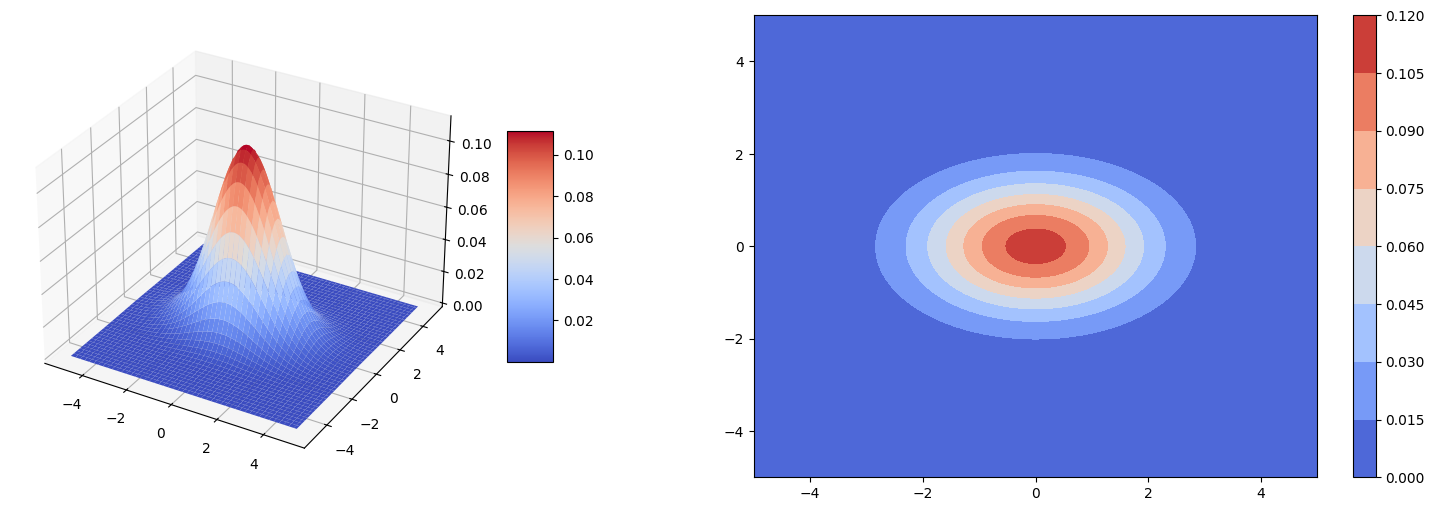

In [5]:
mean = [0, 0]
cov = [
    [2, 0],
    [0, 1]
]

zeta = multivariate_normal(mean=mean, cov=cov)

x = np.arange(-5, 5.01, 0.01)
y = np.arange(-5, 5.01, 0.01)
X, Y = np.meshgrid(x, y)
pos = np.dstack((X, Y))
Z = zeta.pdf(pos)

fig = plt.figure(figsize=(20, 6))

ax1 = fig.add_subplot(121, projection='3d')
surf = ax1.plot_surface(X,Y,Z, cmap=cm.coolwarm)
fig.colorbar(surf, shrink=0.5, aspect=5)

ax2 = fig.add_subplot(122)
cont = ax2.contourf(X,Y,Z, cmap=cm.coolwarm)
fig.colorbar(cont)

plt.show()

#### 2.1.2 Завдання 2.1.2

Зобразіть графік поверхні та контурний графік функції щільності $2$-вимірного нормального розподілу з параметрами
$$\mu = \begin{bmatrix} 1 \\ -1\end{bmatrix}, \qquad
\Sigma = \begin{bmatrix} 2 & -0.5 \\ -0.5 & 1 \end{bmatrix}.$$

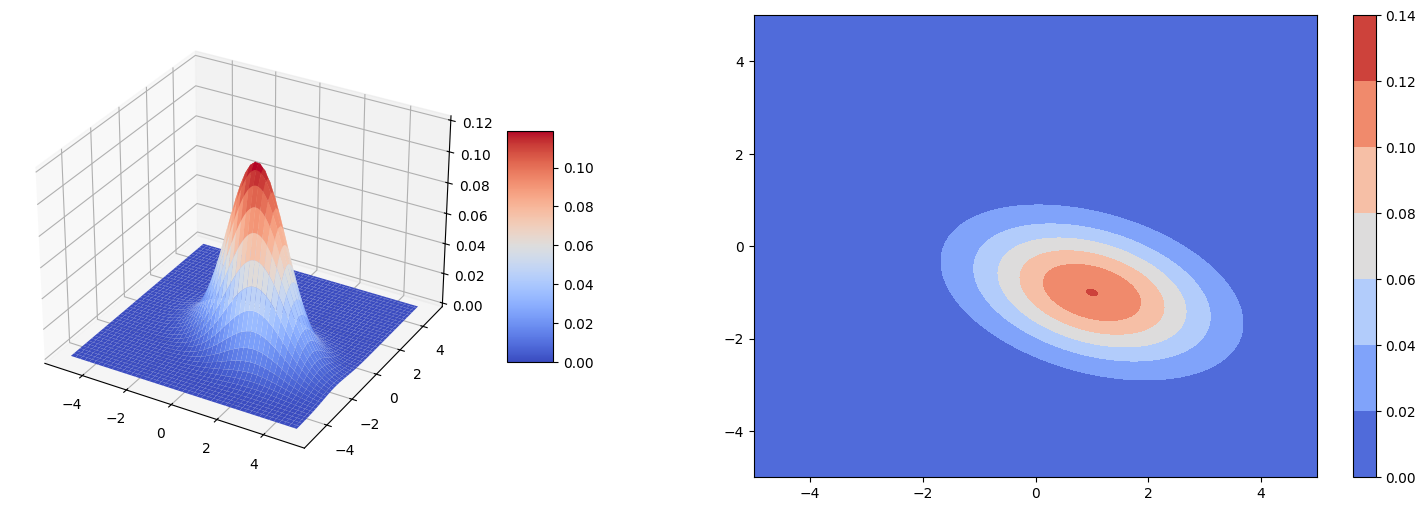

In [6]:
mean = [1, -1]
cov = [
    [2, -0.5],
    [-0.5, 1]
]

zeta = multivariate_normal(mean=mean, cov=cov)

x = np.arange(-5, 5.01, 0.01)
y = np.arange(-5, 5.01, 0.01)
X, Y = np.meshgrid(x, y)
pos = np.dstack((X, Y))
Z = zeta.pdf(pos)

fig = plt.figure(figsize=(20, 6))

ax1 = fig.add_subplot(121, projection='3d')
surf = ax1.plot_surface(X,Y,Z, cmap=cm.coolwarm)
fig.colorbar(surf, shrink=0.5, aspect=5)

ax2 = fig.add_subplot(122)
cont = ax2.contourf(X,Y,Z, cmap=cm.coolwarm)
fig.colorbar(cont)

plt.show()

## 3 Некорельованість не означає незалежність

### 3.1 Задача 1.16.13

Нехай $Z = X Y$, де $X \sim N(0, 1)$ не залежить від $Y$ і $P(Y = 1) = P(Y = -1) = \frac{1}{2}$.
Покажіть, що $Z \sim N(0, 1)$ і що $X$ та $Z$ некорельовані, але залежні.
Знайдіть розподіл пар $(X, Z)$ та $(Y, Z)$, а також розподіл $X + Z$.

1. Згенеруйте $n = 100000$ значень випадкових величин $X, Y$;
2. Отримайте $n = 100000$ значень випадкової величини $Z$;
3. Зобразіть на графіку:
   - нормовану гістограму отриманих $n = 100000$ значень випадкової величини $Z$;
   - функцію щільності випадкової величини $Z$.
4. Виведіть матрицю коваріацій між значеннями випадкових величин $X$ та $Z$.
5. Для значень $X$ та $Z$ побудуйте:
   - нормовану 3D гістограму;
   - контурний графік;
   - діаграму розсіювання.
6. Для значень $Y$ та $Z$ побудуйте:
   - нормовану 3D гістограму;
   - контурний графік;
   - діаграму розсіювання.
7. Зобразіть на графіку:
   - нормовану гістограму $n = 100000$ значень випадкової величини $X+Z$;
   - функцію щільності випадкової величини $X+Z$.

By the law of total probability: $F_{Z}(x) = P(Z=XY <x) = P(XY < x | Y = 1)\cdot P(Y =1) + P(XY < x|Y=-1)\cdot P(Y=-1) = \frac{1}{2} \cdot (P(X < x) + P(-X < x)) = \Phi(x) \Rightarrow Z \sim N(0, 1)$

$cov(X, Z) = E[XZ]-E[X]\cdot E[Z] = E[X^2Y]-E[X]\cdot E[Z]$

$P(X^2\cdot Y< x) = P(X^2\cdot (-Y)<x) \Rightarrow E[X^2\cdot Y] = 0$

$E[Z] = 0$

$cov(X, Z) = 0-0= 0$

$P(X < -1, XY>\frac{1}{2}) = P(X < -1, Y=-1) = P(X < -1) \cdot P(Y = -1) = \Phi(-1) \cdot \frac{1}{2}$

$P(X < -1) \cdot P(XY > \frac{1}{2}) = \Phi(-1)\cdot (1-\Phi(-\frac{1}{2})) = |\Phi(-\frac{1}{2}) \approx 0.3| = \Phi(-1)\cdot 0.7$

Hence, X and Z are not independent.

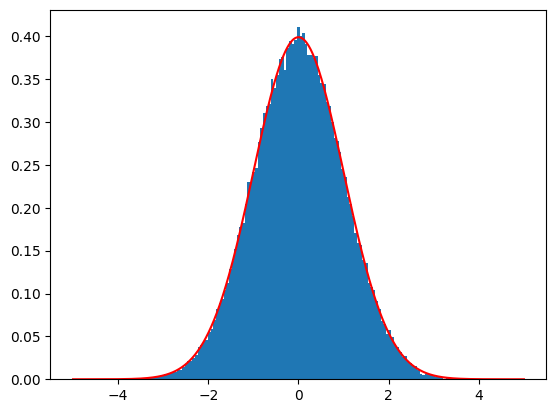

In [23]:
# 3
from scipy.stats import norm

z_rvs = norm.rvs(0, 1, size=100_000)
plt.hist(z_rvs, bins="auto", density=True)
x = np.arange(-5, 5.01, 0.01)
y = norm.pdf(x, 0, 1)
plt.plot(x, y, 'r')
plt.show()


In [8]:
# 4
Cov = [
    [1, 0],
    [0, 1]
]
print("Cov = ")
for row in Cov:
    print(*row)

Cov = 
1 0
0 1


In [7]:
n = 100_000
X = norm.rvs(loc=0, scale=1, size=n)
Y = np.random.choice([-1, 1], size=n, p=[0.5, 0.5])
Z = X*Y

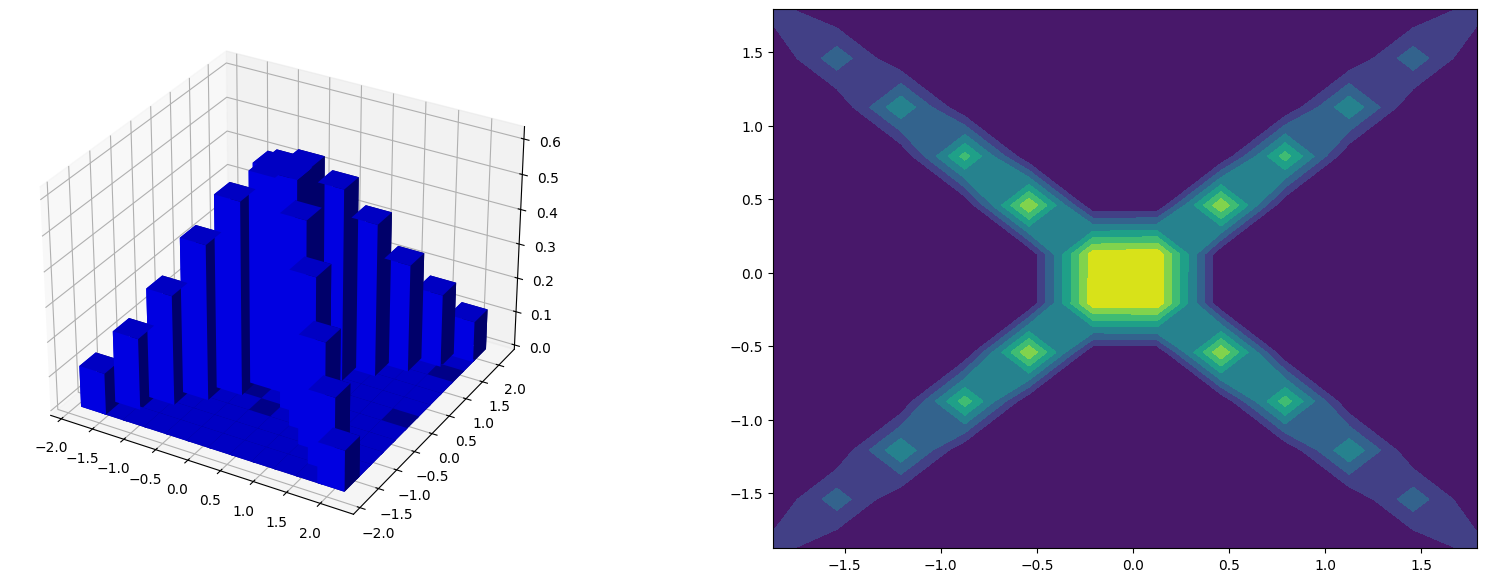

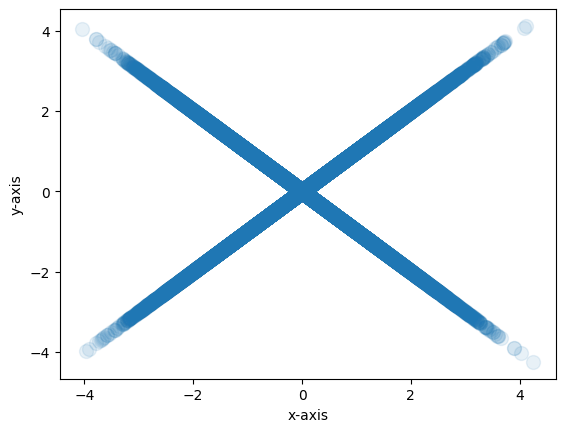

In [6]:
# 5
fig = plt.figure(figsize=(20,7))
ax = fig.add_subplot(121, projection='3d')
ax2 = fig.add_subplot(122)
size = 100_000

hist, xedges, yedges = np.histogram2d(X, Z, bins=12, range = [[-2, 2], [-2, 2]], density=True)

xpos, ypos = np.meshgrid(xedges[:-1] + 0.125, yedges[:-1] + 0.125, indexing="ij")
xpos = xpos.ravel()
ypos = ypos.ravel()
zpos = np.zeros_like(xpos)

dx = dy = 0.4 * np.ones_like(zpos)
dz = hist.ravel()

ax.bar3d(xpos, ypos, zpos, dx, dy, dz, color='b', zsort='average')
x_range = [-2, 2]
y_range = [-2, 2]
x_length = (x_range[1] - x_range[0])
y_length = (y_range[1] - y_range[0])
normed_hist = hist / (size * x_length * y_length)
x, y = np.meshgrid(xedges[:-1] + 0.125, yedges[:-1] + 0.125, indexing="ij")
ax2.contourf(x, y, normed_hist)
plt.show()
plt.scatter(X, Z, s=100, alpha=0.1)
plt.xlabel('x-axis')
plt.ylabel('y-axis')
plt.show()

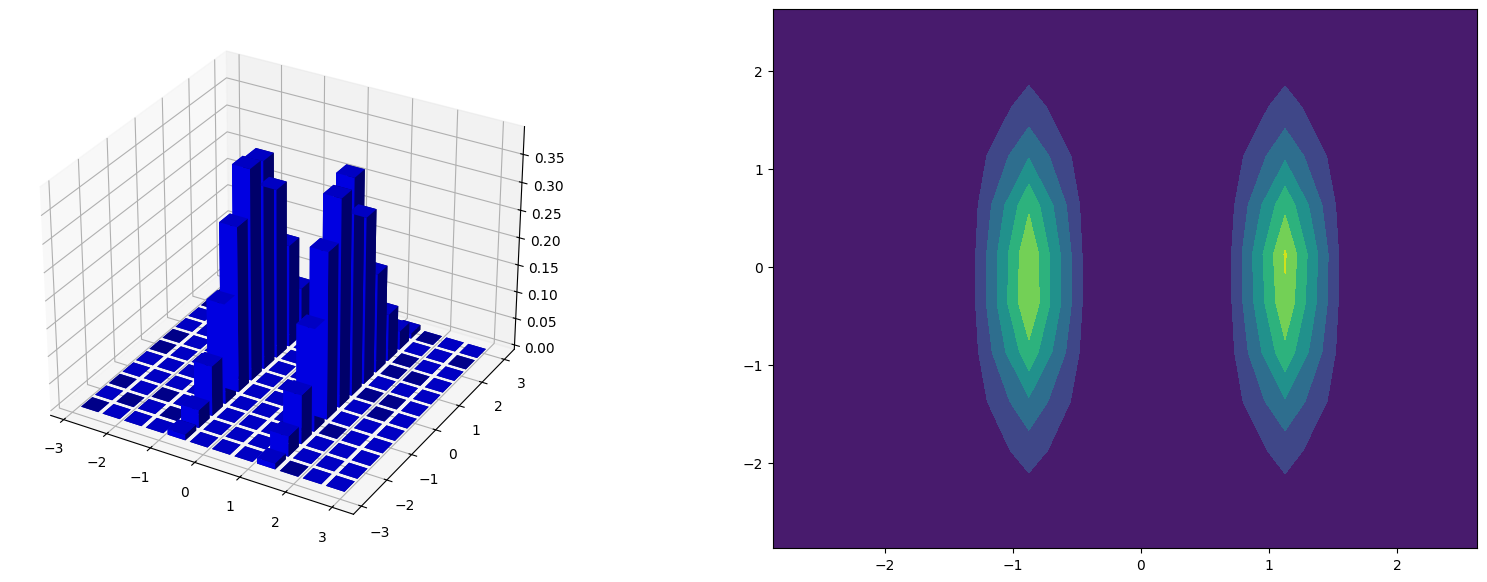

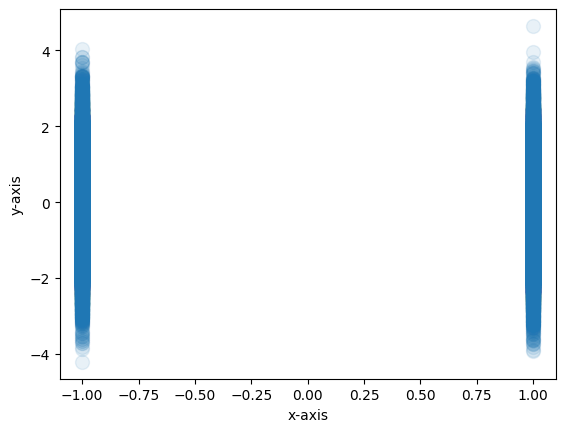

In [13]:
# 6
fig = plt.figure(figsize=(20,7))
ax = fig.add_subplot(121, projection='3d')
ax2 = fig.add_subplot(122)

hist, xedges, yedges = np.histogram2d(Y, Z, bins=12, range = [[-3, 3], [-3, 3]], density=True)

xpos, ypos = np.meshgrid(xedges[:-1] + 0.125, yedges[:-1] + 0.125, indexing="ij")
xpos = xpos.ravel()
ypos = ypos.ravel()
zpos = np.zeros_like(xpos)

dx = dy = 0.4 * np.ones_like(zpos)
dz = hist.ravel()

ax.bar3d(xpos, ypos, zpos, dx, dy, dz, color='b', zsort='average')

x_length = (x_range[1] - x_range[0])
y_length = (y_range[1] - y_range[0])
normed_hist = hist / (size * x_length * y_length)
x, y = np.meshgrid(xedges[:-1] + 0.125, yedges[:-1] + 0.125, indexing="ij")
ax2.contourf(x, y, normed_hist)
plt.show()
plt.scatter(Y, Z, s=100, alpha=0.1)
plt.xlabel('x-axis')
plt.ylabel('y-axis')
plt.show()

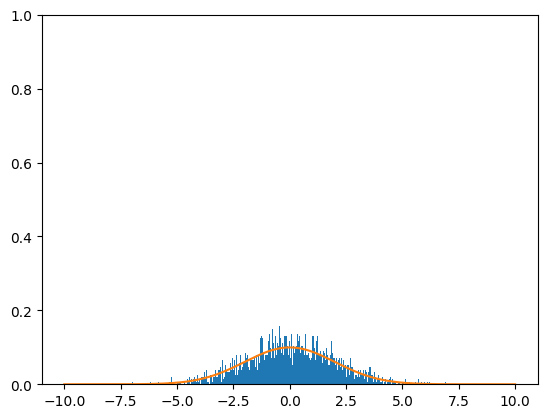

In [22]:
# 7
ksi_rvs = X+Z
x = np.arange(-10, 10.01, 0.01)
y = norm.pdf(x, loc=0, scale=2) / 2
_ = plt.hist(ksi_rvs, density=True, bins="auto")
plt.plot(x, y)
plt.ylim(0, 1)
plt.show()

## 4 Незалежність випадкових величин з Домашньої роботи №8

Розглянемо дві незалежні випадкові величини $\xi_1, \xi_2$ зі стандартного рівномірного розподілу.
Тобто $\xi_1, \xi_2 \sim Exp(1)$.

Тоді випадкові величини
$$
\begin{aligned}
\zeta_1 &= \frac{\xi_1}{\xi_1 + \xi_2} \sim Uniform(0, 1), \\
\zeta_2 &= \xi_1 + \xi_2 \sim \Gamma(2)
\end{aligned}
$$
незалежні.
1. Згенеруйте $n = 100000$ значень випадкових величин $\xi_1, \xi_2$;
2. Отримайте $n = 100000$ значень випадкових величин $\zeta_1, \zeta_2$;
3. Зобразіть на графіку:
   - нормовану гістограму отриманих $n = 100000$ значень випадкової величини $\zeta_1$;
   - функцію щільності випадкової величини $\zeta_1$.
4. Зобразіть на графіку:
   - нормовану гістограму отриманих $n = 100000$ значень випадкової величини $\zeta_2$;
   - функцію щільності випадкової величини $\zeta_2$.
5. Для значень двох незалежних випадкових величин $\eta_1 \sim Uniform(0, 1), \eta_2 \sim \Gamma(2)$ побудуйте:
   - нормовану 3D гістограму;
   - контурний графік;
   - діаграму розсіювання.
6. Для значень $\zeta_1$ та $\zeta_2$ побудуйте:
   - нормовану 3D гістограму;
   - контурний графік;
   - діаграму розсіювання.
7. Виведіть матрицю коваріацій, кореляції Пірсона та Спірмена між значеннями випадкових величин $\zeta_1$ та $\zeta_2$.

In [25]:
from scipy.stats import uniform, expon, gamma

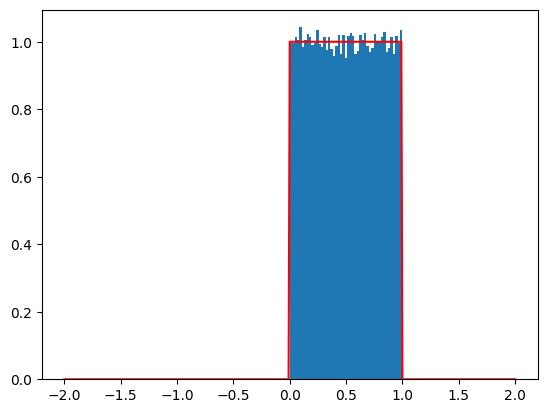

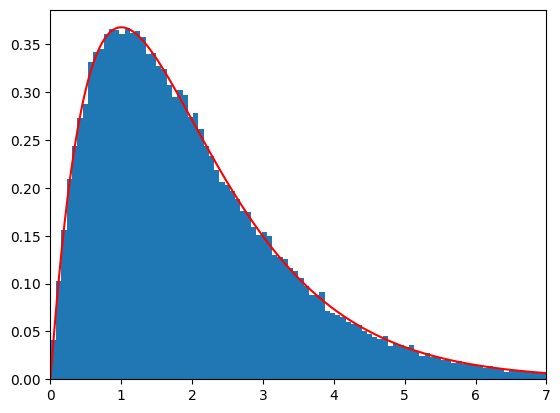

In [26]:
# 1, 2, 3, 4
ksi1 = expon(0, 1)
ksi2 = expon(0, 1)
zeta1 = uniform(0, 1)
zeta2 = gamma(2)
size = 100_000

ksi1_rvs = expon.rvs(0, 1, size=size)
ksi2_rvs = expon.rvs(0, 1, size=size)

zeta1_rvs = ksi1_rvs/(ksi1_rvs+ksi2_rvs)
zeta2_rvs = ksi1_rvs+ksi2_rvs

plt.hist(zeta1_rvs, bins="auto", density=True)
x = np.arange(-2, 2.01, 0.01)
y = uniform.pdf(x, 0, 1)
plt.plot(x, y, 'r')
plt.show()

plt.hist(zeta2_rvs, bins="auto", density=True)
x = np.arange(-2, 7.01, 0.01)
y = gamma.pdf(x, a=2, loc=0, scale=1)
plt.plot(x, y, 'r')
plt.xlim(0, 7)
plt.show()

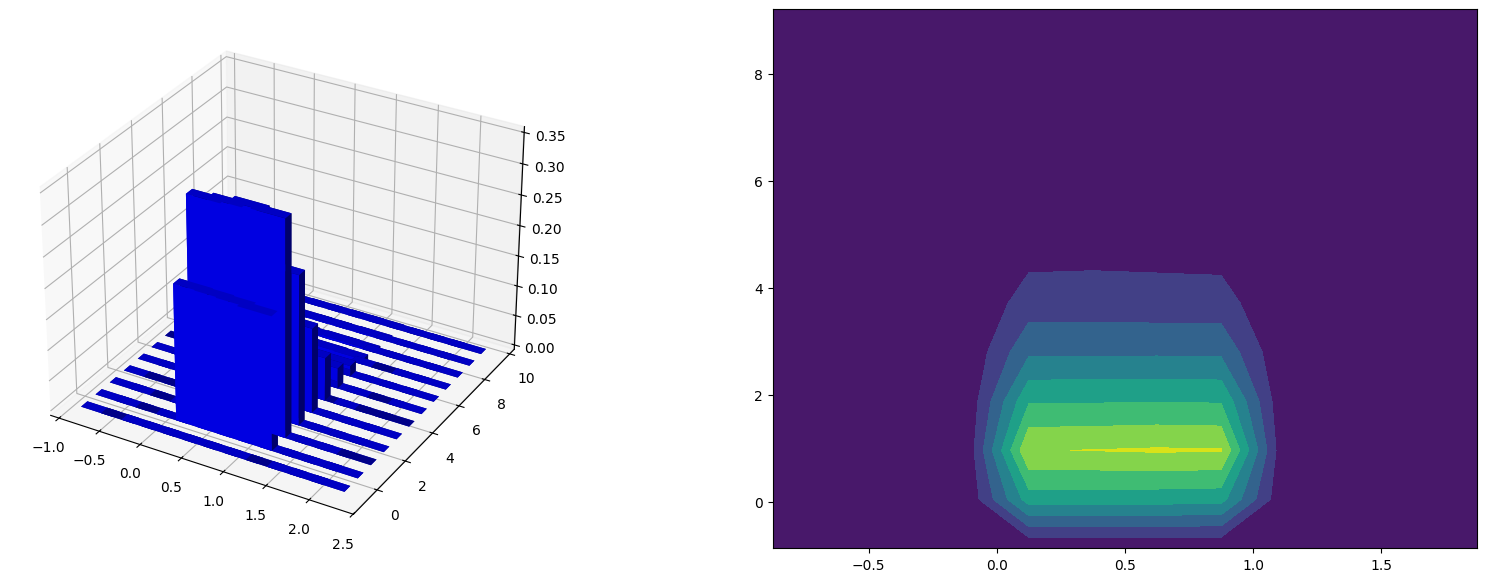

In [27]:
# 5
fig = plt.figure(figsize=(20,7))
ax = fig.add_subplot(121, projection='3d')
ax2 = fig.add_subplot(122)

eta1 = uniform.rvs(0, 1, size=size)
eta2 = gamma.rvs(a=2, loc=0, scale=1, size=size)

hist, xedges, yedges = np.histogram2d(eta1, eta2, bins=12, range = [[-1, 2], [-1, 10]], density=True)

xpos, ypos = np.meshgrid(xedges[:-1] + 0.125, yedges[:-1] + 0.125, indexing="ij")
xpos = xpos.ravel()
ypos = ypos.ravel()
zpos = np.zeros_like(xpos)

dx = dy = 0.4 * np.ones_like(zpos)
dz = hist.ravel()

ax.bar3d(xpos, ypos, zpos, dx, dy, dz, color='b', zsort='average')

x_range = [-1, 2]
y_range = [-1, 10]
x_length = (x_range[1] - x_range[0])
y_length = (y_range[1] - y_range[0])
normed_hist = hist / (size * x_length * y_length)
x, y = np.meshgrid(xedges[:-1] + 0.125, yedges[:-1] + 0.125, indexing="ij")
ax2.contourf(x, y, normed_hist)
plt.show()


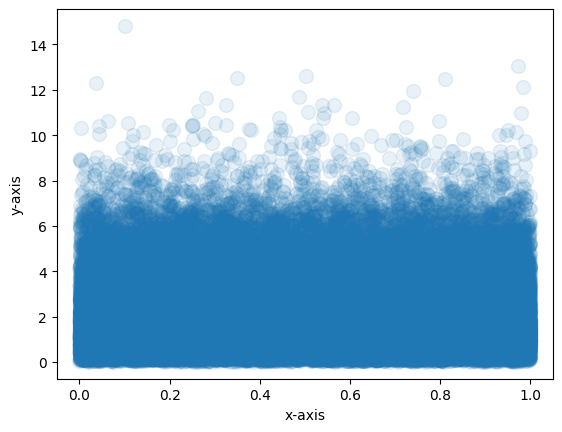

In [28]:
plt.scatter(eta1, eta2, s=100, alpha=0.1)
plt.xlabel('x-axis')
plt.ylabel('y-axis')
plt.show()

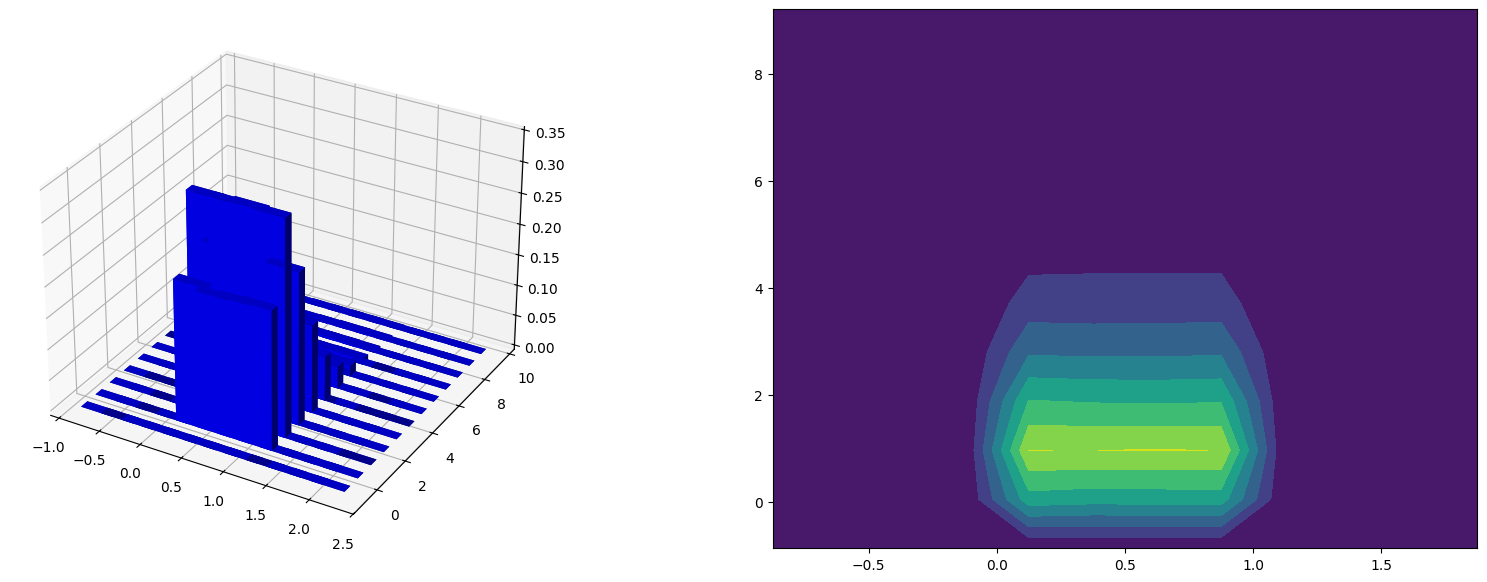

In [31]:
# 6
fig = plt.figure(figsize=(20,7))
ax = fig.add_subplot(121, projection='3d')
ax2 = fig.add_subplot(122)

hist, xedges, yedges = np.histogram2d(zeta1_rvs, zeta2_rvs, bins=12, range = [[-1, 2], [-1, 10]], density=True)

xpos, ypos = np.meshgrid(xedges[:-1] + 0.125, yedges[:-1] + 0.125, indexing="ij")
xpos = xpos.ravel()
ypos = ypos.ravel()
zpos = np.zeros_like(xpos)

dx = dy = 0.4 * np.ones_like(zpos)
dz = hist.ravel()

ax.bar3d(xpos, ypos, zpos, dx, dy, dz, color='b', zsort='average')

x_length = (x_range[1] - x_range[0])
y_length = (y_range[1] - y_range[0])
normed_hist = hist / (size * x_length * y_length)
x, y = np.meshgrid(xedges[:-1] + 0.125, yedges[:-1] + 0.125, indexing="ij")
ax2.contourf(x, y, normed_hist)
plt.show()

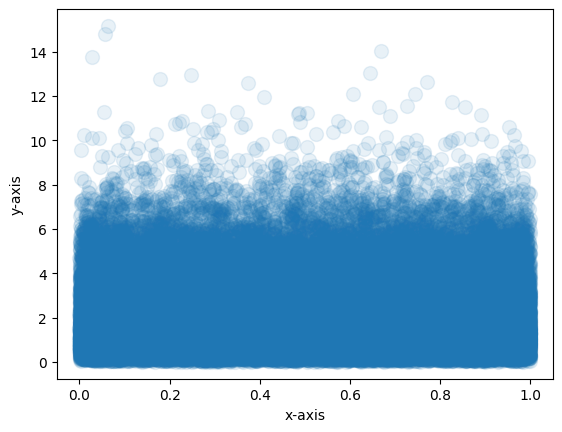

In [32]:
plt.scatter(zeta1_rvs, zeta2_rvs, s=100, alpha=0.1)
plt.xlabel('x-axis')
plt.ylabel('y-axis')
plt.show()

In [33]:
# 7
np.corrcoef(zeta1_rvs, zeta2_rvs)

array([[1.        , 0.00260308],
       [0.00260308, 1.        ]])

In [34]:
from scipy.stats.mstats import spearmanr
print(f"Spearman correlation = {spearmanr(zeta1_rvs, zeta2_rvs)[0]}")

Spearman correlation = 0.001903948529086395


In [35]:
from scipy.stats.mstats import pearsonr
print(f"Pearson correlation = {pearsonr(zeta1_rvs, zeta2_rvs)[0]}")

Pearson correlation = 0.0026030826557965512


## 5 Генерування залежних випадкових величин

### 5.1 Нормальний розподіл

Нехай $\zeta = (\zeta_1, \zeta_2)^T \sim N_2(\textbf{0}, I)$, тобто $\zeta_1, \zeta_2 \sim N(0, 1)$ &mdash; незалежні,
$A$ &mdash; матриця $2 \times 2$, $m$ &mdash; вектор $2 \times 1$.
Тоді
$$A \zeta + m \sim N_2 (m, A A^T).$$

#### 5.1.1 Від'ємна кореляція

Розглянемо дві незалежні випадкові величини $\xi_1, \xi_2$ зі стандартного нормального розподілу.
Тобто $\xi_1, \xi_2 \sim N(0, 1)$.

Згенеруйте випадковий вектор $\zeta = (\zeta_1, \zeta_2)$ з $2$-вимірного нормального розподілу з параметрами
$$
\mu = \begin{bmatrix} 1 \\ -1 \end{bmatrix}, \qquad
\Sigma = \begin{bmatrix} 2 & -0.5 \\ -0.5 & 1 \end{bmatrix}
$$
за допомогою лінійного перетворення випадкових величин $\xi_1, \xi_2$ та розкладу Холецького матриці $\Sigma$.

1. Згенеруйте $n = 100000$ значень випадкових величин $\xi_1, \xi_2 \sim N(0,1)$;
2. Отримайте $n = 100000$ значень $\zeta$;
3. Зобразіть на графіку:
   - нормовану гістограму отриманих $n = 100000$ значень випадкової величини $\xi_1$;
   - функцію щільності випадкової величини $\xi_1$.
4. Зобразіть на графіку:
   - нормовану гістограму отриманих $n = 100000$ значень випадкової величини $\xi_2$;
   - функцію щільності випадкової величини $\xi_2$.
5. Для значень $\zeta_1$ та $\zeta_2$ побудуйте:
   - нормовану 3D гістограму;
   - контурний графік;
   - діаграму розсіювання.
6. Виведіть матрицю коваріацій, кореляції Пірсона та Спірмена між значеннями випадкових величин $\zeta_1$ та $\zeta_2$.
7. Зобразіть на графіку:
   - нормовану гістограму отриманих $n = 100000$ значень випадкової величини $\zeta_1$;
   - функцію щільності випадкової величини $\zeta_1$.
8. Зобразіть на графіку:
   - нормовану гістограму отриманих $n = 100000$ значень випадкової величини $\zeta_2$;
   - функцію щільності випадкової величини $\zeta_2$.

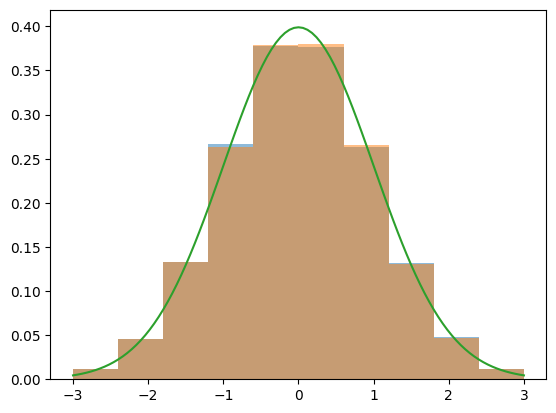

In [37]:
# 1, 2, 3, 4
n = 100_000
mean = np.array([1, -1])
Sigma = np.array([
    [2, -0.5],
    [-0.5, 1]
])
A = np.linalg.cholesky(Sigma)

ksi1, ksi2 = np.random.normal(0, 1, size=(2, n))
zeta = A.dot(np.array([ksi1, ksi2])) + mean[:, None]

x = np.linspace(-3, 3, 101)
plt.hist(ksi1, density=True, alpha=0.5, range=(-3, 3))
plt.hist(ksi2, density=True, alpha=0.5, range=(-3, 3))
plt.plot(x, norm.pdf(x, 0, 1))
plt.show()

In [39]:
zeta1 = zeta[0]
zeta2 = zeta[1]

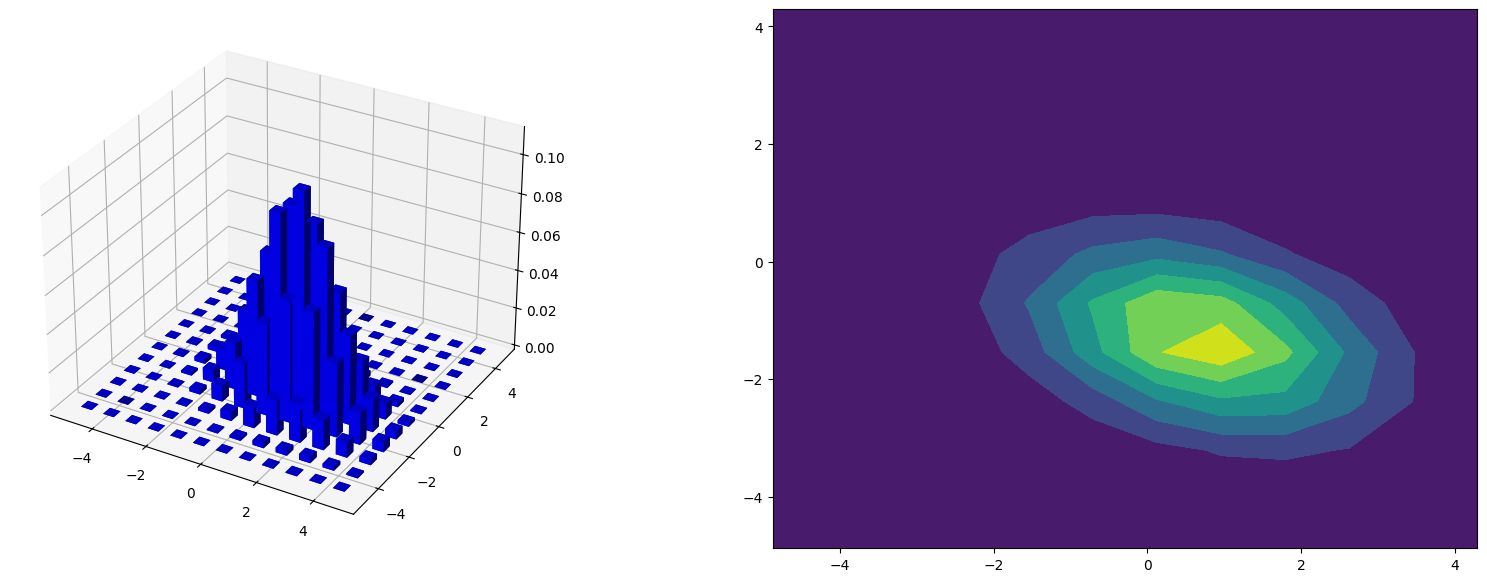

In [40]:
# 5
fig = plt.figure(figsize=(20,7))
ax = fig.add_subplot(121, projection='3d')
ax2 = fig.add_subplot(122)

hist, xedges, yedges = np.histogram2d(zeta1, zeta2, bins=12, range = [[-5, 5], [-5, 5]], density=True)

xpos, ypos = np.meshgrid(xedges[:-1] + 0.125, yedges[:-1] + 0.125, indexing="ij")
xpos = xpos.ravel()
ypos = ypos.ravel()
zpos = np.zeros_like(xpos)

dx = dy = 0.4 * np.ones_like(zpos)
dz = hist.ravel()

ax.bar3d(xpos, ypos, zpos, dx, dy, dz, color='b', zsort='average')

x_length = (x_range[1] - x_range[0])
y_length = (y_range[1] - y_range[0])
normed_hist = hist / (size * x_length * y_length)
x, y = np.meshgrid(xedges[:-1] + 0.125, yedges[:-1] + 0.125, indexing="ij")
ax2.contourf(x, y, normed_hist)
plt.show()

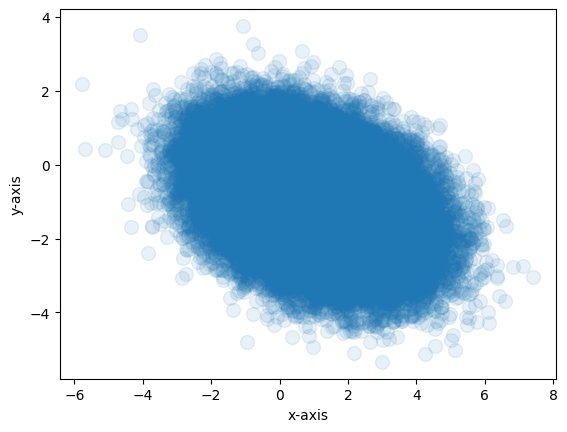

In [41]:
plt.scatter(zeta1, zeta2, s=100, alpha=0.1)
plt.xlabel('x-axis')
plt.ylabel('y-axis')
plt.show()

In [42]:
# 6
np.corrcoef(zeta1, zeta2)

array([[ 1.        , -0.35316891],
       [-0.35316891,  1.        ]])

In [43]:
print(f"Spearman correlation = {spearmanr(zeta1, zeta2)[0]}")
print(f"Pearson correlation = {pearsonr(zeta1, zeta2)[0]}")

Spearman correlation = -0.33870704975307075
Pearson correlation = -0.3531689145544983


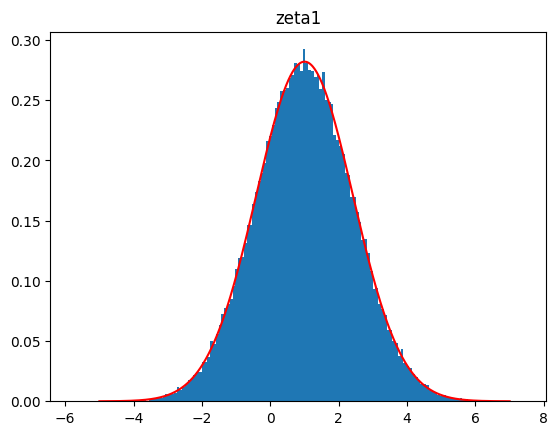

In [44]:
# 7
plt.hist(zeta1, bins="auto", density=True)
x = np.arange(-5, 7.01, 0.01)
y = norm.pdf(x, 1, 2**0.5)
plt.plot(x, y, 'r')
plt.title('zeta1')
plt.show()

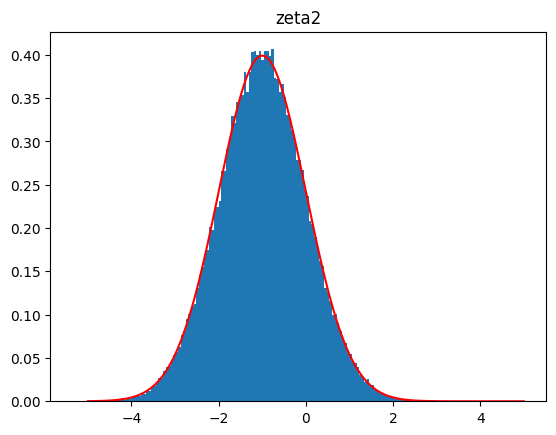

In [45]:
# 8
plt.hist(zeta2, bins="auto", density=True)
x = np.arange(-5, 5.01, 0.01)
y = norm.pdf(x, -1, 1)
plt.plot(x, y, 'r')
plt.title('zeta2')
plt.show()

### 5.2 Експоненційний розподіл

За метеріалами статті

*A. J. Lawrance, P. A. W. Lewis.
“Simple Dependent Pairs of Exponential and Uniform Random Variables.”
Operations Research, vol. 31, no. 6, 1983, pp. 1179–1197.*

Оригінал статті дивіться в прикріпленому файлі [lab_9_paper.pdf](https://github.com/Slavastas119/Probability-Theory-2-year-students/blob/master/%D0%9B%D0%B0%D0%B1%D0%BE%D1%80%D0%B0%D1%82%D0%BE%D1%80%D0%BD%D0%B5%20%D0%B7%D0%B0%D0%BD%D1%8F%D1%82%D1%82%D1%8F%209/lab_9_paper.pdf)
або [за посиланням](https://pdfs.semanticscholar.org/1ceb/fbbe20644a4e9d3a6eaa3698777a8b0169a6.pdf).

#### 5.2.1 Від'ємна кореляція

Розглянемо дві незалежні випадкові величини $u_1, u_2$ зі стандартного рівномірного розподілу
та незалежні від них, але залежні між собою, випадкові величини $\eta_1, \eta_2$ з розподілу Бернуллі з параметром $p$.
Тобто $u_1, u_2 \sim Uniform(0, 1), \eta_1, \eta_2 \sim Bernoulli(p)$.

Тоді
$$
\begin{aligned}
\xi_1 &= F^{-1}(u_1) \sim Exp(1), \\
\xi_2 &= F^{-1}(u_2) \sim Exp(1), \\
\xi_1^a &= F^{-1}(1-u_1) \sim Exp(1), \\
\xi_2^a &= F^{-1}(1-u_2) \sim Exp(1),
\end{aligned}
$$
де $F$ &mdash; функція розподілу стандартного експоненційного розподілу.

Випадкові величини $\eta_1, \eta_2$ залежні таким чином:
$$
\left\{
\begin{aligned}
P(\eta_1 = 0, \eta_2 = 0) &= 0, \\
P(\eta_1 = 0, \eta_2 = 1) &= 1 - p, \\
P(\eta_1 = 1, \eta_2 = 0) &= 1 - p, \\
P(\eta_1 = 1, \eta_2 = 1) &= 2 p - 1,
\end{aligned}
\right.
\quad p \geq 1/2, \qquad \qquad
\left\{
\begin{aligned}
P(\eta_1 = 0, \eta_2 = 0) &= 1 - 2 p, \\
P(\eta_1 = 0, \eta_2 = 1) &= p, \\
P(\eta_1 = 1, \eta_2 = 0) &= p, \\
P(\eta_1 = 1, \eta_2 = 1) &= 0,
\end{aligned}
\right.
\quad p \leq 1/2.
$$

Тоді випадкові величини
$$
\begin{aligned}
\zeta_1 &= (1 - p) \xi_1 + \eta_1 \xi_2 \sim Exp(1), \\
\zeta_2 &= (1 - p) \xi_2^a + \eta_2 \xi_1^a \sim Exp(1)
\end{aligned}
$$
залежні та мають коефіцієнт кореляції
$$
Corr(\zeta_1, \zeta_2) =
\left\{
\begin{aligned}
&2 p (1 - p)(-0.6449) - (1 - p)^2, & p \geq 1/2, \\
&2 p (1 - p)(-0.6449) - p^2, & p \leq 1/2.
\end{aligned}
\right.
$$

Для параметра $p = 0.5$
1. Згенеруйте $n = 100000$ значень випадкових величин $u_1, u_2, \eta_1, \eta_2$;
2. Отримайте $n = 100000$ значень $\xi_1, \xi_2, \xi_1^a, \xi_2^a, \zeta_1, \zeta_2$;
3. Зобразіть на графіку:
   - нормовану гістограму отриманих $n = 100000$ значень випадкової величини $\xi_1$;
   - функцію щільності випадкової величини $\xi_1$.
4. Зобразіть на графіку:
   - нормовану гістограму отриманих $n = 100000$ значень випадкової величини $\xi_2$;
   - функцію щільності випадкової величини $\xi_2$.
3. Зобразіть на графіку:
   - нормовану гістограму отриманих $n = 100000$ значень випадкової величини $\xi_1^a$;
   - функцію щільності випадкової величини $\xi_1^a$.
4. Зобразіть на графіку:
   - нормовану гістограму отриманих $n = 100000$ значень випадкової величини $\xi_2^a$;
   - функцію щільності випадкової величини $\xi_2^a$.
5. Для значень $\zeta_1$ та $\zeta_2$ побудуйте:
   - нормовану 3D гістограму;
   - контурний графік;
   - діаграму розсіювання.
6. Виведіть теоретичну кореляцію, матрицю коваріацій, кореляції Пірсона та Спірмена між значеннями випадкових величин $\zeta_1$ та $\zeta_2$.
7. Зобразіть на графіку:
   - нормовану гістограму отриманих $n = 100000$ значень випадкової величини $\zeta_1$;
   - функцію щільності випадкової величини $\zeta_1$.
8. Зобразіть на графіку:
   - нормовану гістограму отриманих $n = 100000$ значень випадкової величини $\zeta_2$;
   - функцію щільності випадкової величини $\zeta_2$.

In [46]:
# 1
from scipy.stats import bernoulli
n = 100_000
u1_rvs = uniform.rvs(size=n)
u2_rvs = uniform.rvs(size=n)
eta1_rvs = bernoulli.rvs(0.5, size=n)
eta2_rvs = bernoulli.rvs(0.5, size=n)

In [47]:
# 2
def invF(x):
    if x < 1:
        return -np.log(1-x)
    else:
        return 0
ksi1_rvs = [invF(el) for el in u1_rvs]
ksi2_rvs = [invF(el) for el in u2_rvs]
ksi1_a_rvs = [invF(1-el) for el in u1_rvs]
ksi2_a_rvs = [invF(1-el) for el in u2_rvs]
zeta1_rvs = []
zeta2_rvs = []
for i in range(size):
    zeta1_rvs.append(0.5*ksi1_rvs[i]+eta1_rvs[i]*ksi2_rvs[i])
    zeta2_rvs.append(0.5*ksi2_a_rvs[i]+eta2_rvs[i]*ksi1_a_rvs[i])

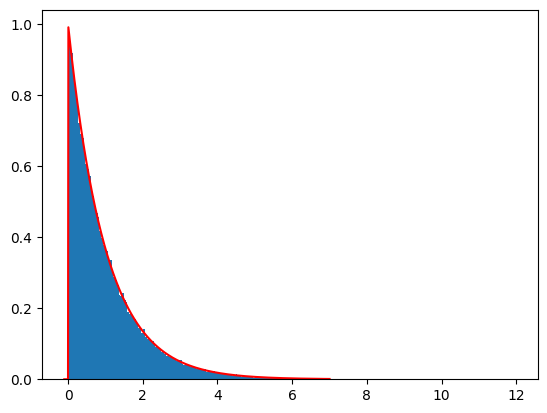

In [48]:
# 3
x = np.arange(-0.1, 7.01, 0.01)
y = expon.pdf(x, loc=0, scale=1)
plt.hist(ksi1_rvs, density=True, bins="auto")
plt.plot(x, y, color="r")
plt.show()

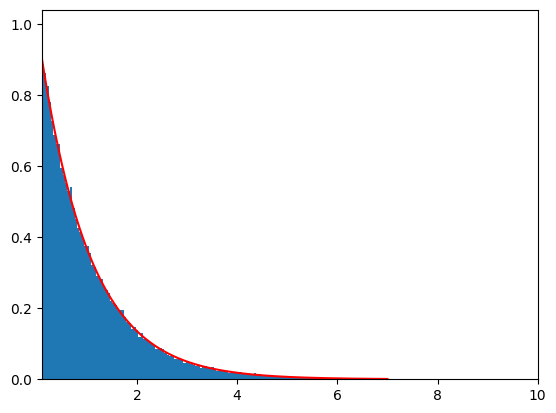

In [49]:
# 4
plt.hist(ksi2_rvs, density=True, bins="auto")
plt.plot(x, y, color="r")
plt.xlim(0.1, 10)
plt.show()

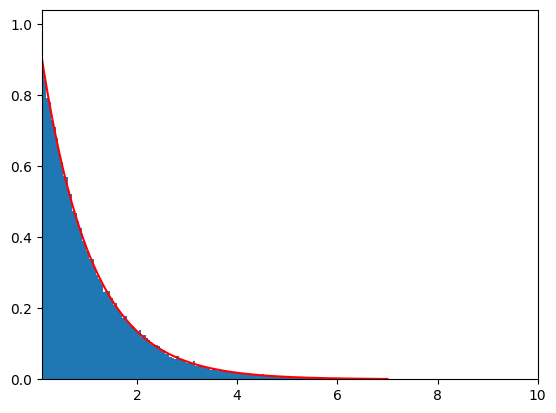

In [50]:
# 5
plt.hist(ksi1_a_rvs, density=True, bins="auto")
plt.plot(x, y, color="r")
plt.xlim(0.1, 10)
plt.show()

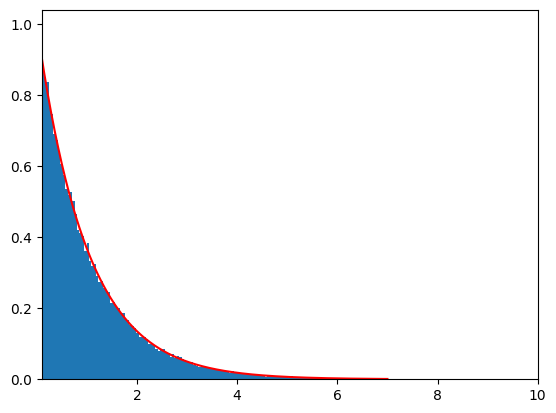

In [51]:
# 6
plt.hist(ksi2_a_rvs, density=True, bins="auto")
plt.plot(x, y, color="r")
plt.xlim(0.1, 10)
plt.show()

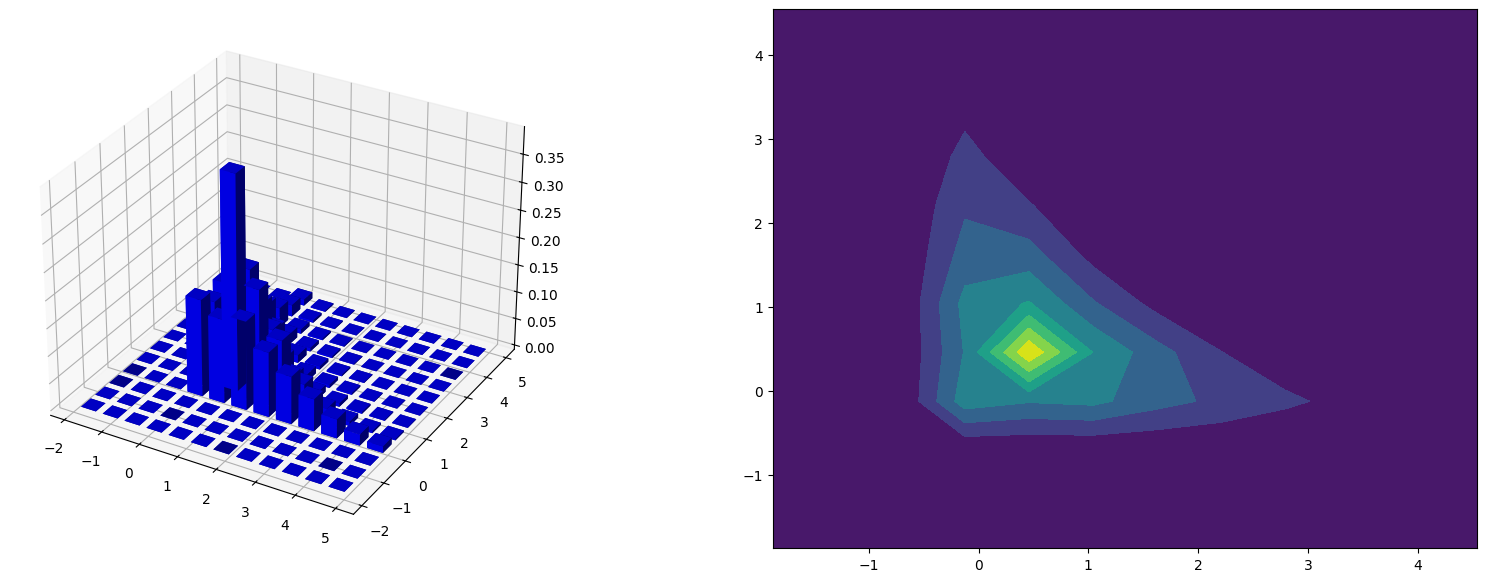

In [52]:
# 7
fig = plt.figure(figsize=(20,7))
ax = fig.add_subplot(121, projection='3d')
ax2 = fig.add_subplot(122)

hist, xedges, yedges = np.histogram2d(zeta1_rvs, zeta2_rvs, bins=12, range = [[-2, 5], [-2, 5]], density=True)

xpos, ypos = np.meshgrid(xedges[:-1] + 0.125, yedges[:-1] + 0.125, indexing="ij")
xpos = xpos.ravel()
ypos = ypos.ravel()
zpos = np.zeros_like(xpos)

dx = dy = 0.4 * np.ones_like(zpos)
dz = hist.ravel()

ax.bar3d(xpos, ypos, zpos, dx, dy, dz, color='b', zsort='average')

x_length = (x_range[1] - x_range[0])
y_length = (y_range[1] - y_range[0])
normed_hist = hist / (size * x_length * y_length)
x, y = np.meshgrid(xedges[:-1] + 0.125, yedges[:-1] + 0.125, indexing="ij")
ax2.contourf(x, y, normed_hist)
plt.show()

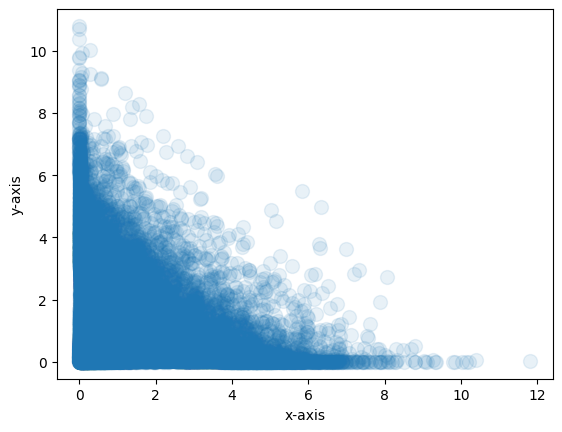

In [55]:
plt.scatter(zeta1_rvs, zeta2_rvs, s=100, alpha=0.1)
plt.xlabel('x-axis')
plt.ylabel('y-axis')
plt.show()

In [56]:
p = 0.5
print(f"Theoretical correlation of zeta1, zeta2: {2*p*(1-p)*(-0.6449)-(1-p)**2}")
print(np.corrcoef(zeta1_rvs, zeta2_rvs))
print(f"Spearman correlation = {spearmanr(zeta1_rvs, zeta2_rvs)[0]}")
print(f"Pearson correlation = {pearsonr(zeta1_rvs, zeta2_rvs)[0]}")

Theoretical correlation of zeta1, zeta2: -0.57245
[[ 1.         -0.32572118]
 [-0.32572118  1.        ]]
Spearman correlation = -0.38901265000818935
Pearson correlation = -0.32572118209319


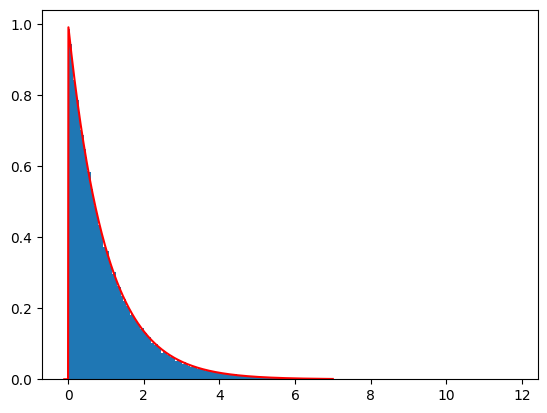

In [57]:
# 9
plt.hist(zeta1_rvs, density=True, bins="auto")
x = np.arange(-0.1, 7.01, 0.01)
y = expon.pdf(x, loc=0, scale=1)
plt.plot(x, y, color="r")
plt.show()

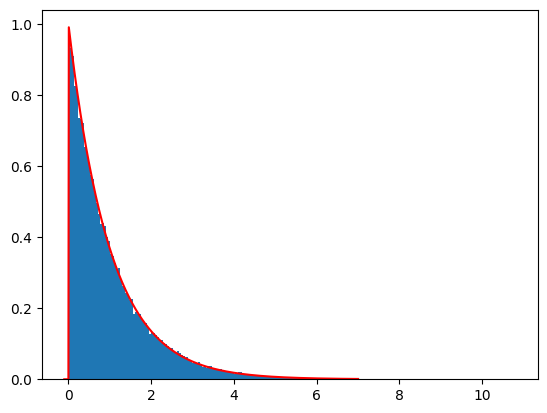

In [58]:
# 10
plt.hist(zeta2_rvs, density=True, bins="auto")
x = np.arange(-0.1, 7.01, 0.01)
y = expon.pdf(x, loc=0, scale=1)
plt.plot(x, y, color="r")
plt.show()

### 5.3 Рівномірний розподіл

За метеріалами статті

*A. J. Lawrance, P. A. W. Lewis.
“Simple Dependent Pairs of Exponential and Uniform Random Variables.”
Operations Research, vol. 31, no. 6, 1983, pp. 1179–1197.*

Оригінал статті дивіться в прикріпленому файлі [lab_9_paper.pdf](https://github.com/Slavastas119/Probability-Theory-2-year-students/blob/master/%D0%9B%D0%B0%D0%B1%D0%BE%D1%80%D0%B0%D1%82%D0%BE%D1%80%D0%BD%D0%B5%20%D0%B7%D0%B0%D0%BD%D1%8F%D1%82%D1%82%D1%8F%209/lab_9_paper.pdf)
або [за посиланням](https://pdfs.semanticscholar.org/1ceb/fbbe20644a4e9d3a6eaa3698777a8b0169a6.pdf).

#### 5.3.1 Від'ємна кореляція

Розглянемо дві незалежні випадкові величини $\xi_1, \xi_2$ зі стандартного рівномірного розподілу
та незалежні від них, але залежні між собою, випадкові величини $\eta_1, \eta_2$ з розподілу Бернуллі з параметром $p$.
Тобто $\xi_1, \xi_2 \sim Uniform(0, 1), \eta_1, \eta_2 \sim Bernoulli(p)$.

Випадкові величини $\eta_1, \eta_2$ залежні таким чином:
$$
\left\{
\begin{aligned}
P(\eta_1 = 0, \eta_2 = 0) &= 0, \\
P(\eta_1 = 0, \eta_2 = 1) &= 1 - p, \\
P(\eta_1 = 1, \eta_2 = 0) &= 1 - p, \\
P(\eta_1 = 1, \eta_2 = 1) &= 2 p - 1,
\end{aligned}
\right.
\quad p \geq 1/2, \qquad \qquad
\left\{
\begin{aligned}
P(\eta_1 = 0, \eta_2 = 0) &= 1 - 2 p, \\
P(\eta_1 = 0, \eta_2 = 1) &= p, \\
P(\eta_1 = 1, \eta_2 = 0) &= p, \\
P(\eta_1 = 1, \eta_2 = 1) &= 0,
\end{aligned}
\right.
\quad p \leq 1/2.
$$

Тоді випадкові величини
$$
\begin{aligned}
\zeta_1 &= 1 - \xi_1^{(1 - p)} \xi_2^{\eta_1} \sim Uniform(0, 1), \\
\zeta_2 &= 1 - (1-\xi_2)^{(1 - p)} (1-\xi_1)^{\eta_2} \sim Uniform(0, 1)
\end{aligned}
$$
залежні та мають коефіцієнт кореляції
$$
Corr(\zeta_1, \zeta_2) =
\left\{
\begin{aligned}
&\frac{-3 (1-p) (4 + 5(1-p) + 6(1-p)^2 + (1-p)^3)}{(2-p)^2 (3-p)^2}, & p \geq 1/2, \\
&\frac{-3 p (2 + 3(1-p) - (1-p)^2)}{(2-p)^2 (3-p)}, & p \leq 1/2.
\end{aligned}
\right.
$$

Для параметра $p = 0.5$
1. Згенеруйте $n = 100000$ значень випадкових величин $\xi_1, \xi_2, \eta_1, \eta_2$;
2. Отримайте $n = 100000$ значень $\zeta_1, \zeta_2$;
3. Зобразіть на графіку:
   - нормовану гістограму отриманих $n = 100000$ значень випадкової величини $\xi_1$;
   - функцію щільності випадкової величини $\xi_1$.
4. Зобразіть на графіку:
   - нормовану гістограму отриманих $n = 100000$ значень випадкової величини $\xi_2$;
   - функцію щільності випадкової величини $\xi_2$.
5. Для значень $\zeta_1$ та $\zeta_2$ побудуйте:
   - нормовану 3D гістограму;
   - контурний графік;
   - діаграму розсіювання.
6. Виведіть теоретичну кореляцію, матрицю коваріацій, кореляції Пірсона та Спірмена між значеннями випадкових величин $\zeta_1$ та $\zeta_2$.
7. Зобразіть на графіку:
   - нормовану гістограму отриманих $n = 100000$ значень випадкової величини $\zeta_1$;
   - функцію щільності випадкової величини $\zeta_1$.
8. Зобразіть на графіку:
   - нормовану гістограму отриманих $n = 100000$ значень випадкової величини $\zeta_2$;
   - функцію щільності випадкової величини $\zeta_2$.

In [59]:
# 1
n = 100_000
ksi1_rvs = uniform.rvs(size=n)
ksi2_rvs = uniform.rvs(size=n)
eta1_rvs = bernoulli.rvs(0.5, size=n)
eta2_rvs = bernoulli.rvs(0.5, size=n)


In [60]:
# 2
p = 0.5
zeta1_rvs = []
zeta2_rvs = []
for i in range(size):
    zeta1_rvs.append(1-ksi1_rvs[i]**(1-p)*ksi2_rvs[i]**eta1_rvs[i])
    zeta2_rvs.append(1-(1-ksi2_rvs[i])**(1-p)*(1-ksi1_rvs[i])**eta2_rvs[i])

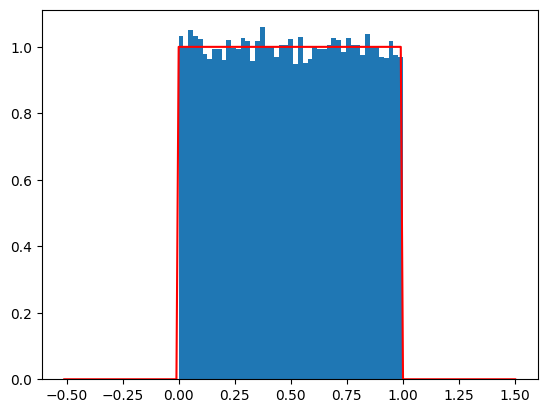

In [61]:
# 3
x = np.arange(-0.51, 1.51, 0.01)
y = uniform.pdf(x, loc=0, scale=1)
plt.hist(ksi1_rvs, density=True, bins="auto")
plt.plot(x, y, color="r")
plt.show()

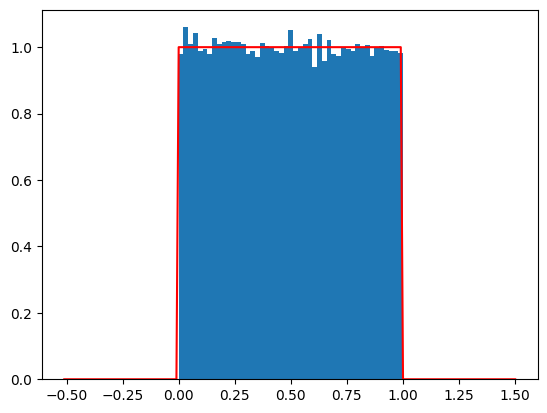

In [62]:
# 4
x = np.arange(-0.51, 1.51, 0.01)
y = uniform.pdf(x, loc=0, scale=1)
plt.hist(ksi2_rvs, density=True, bins="auto")
plt.plot(x, y, color="r")
plt.show()

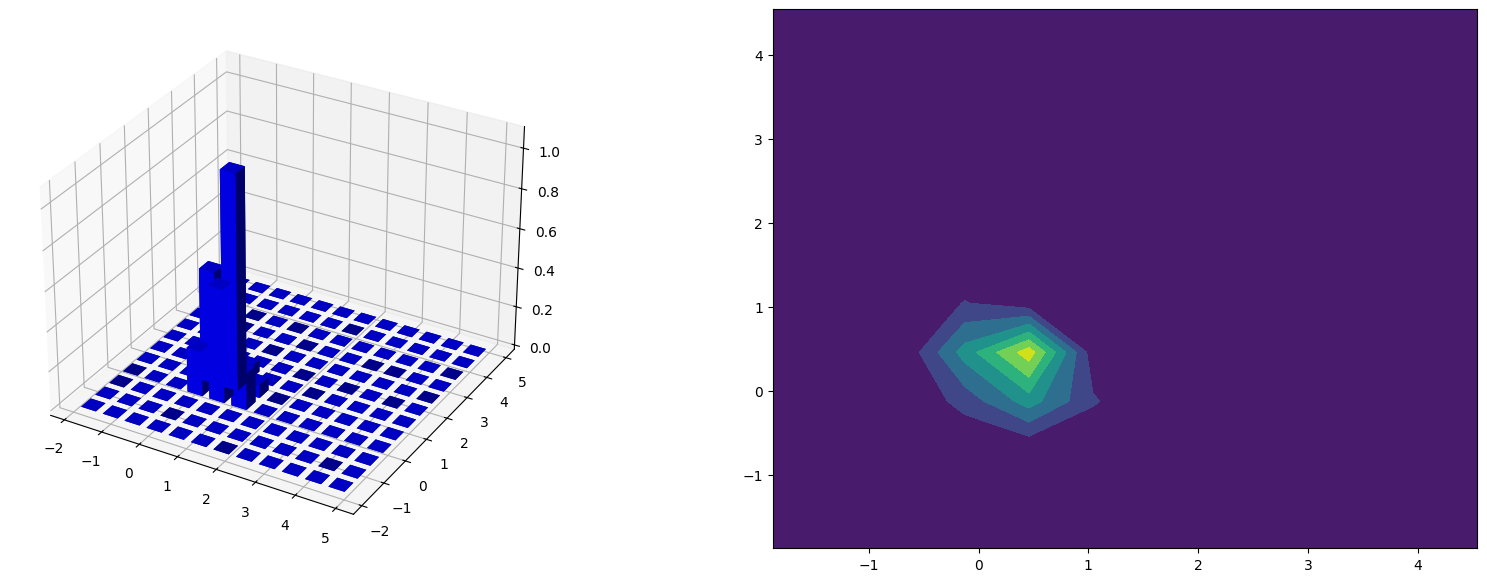

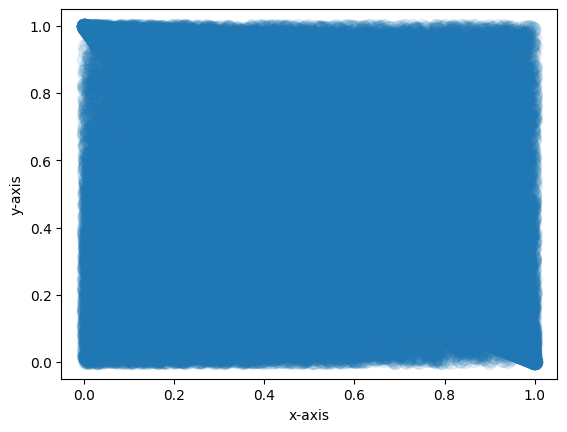

In [63]:
# 5
fig = plt.figure(figsize=(20,7))
ax = fig.add_subplot(121, projection='3d')
ax2 = fig.add_subplot(122)

hist, xedges, yedges = np.histogram2d(zeta1_rvs, zeta2_rvs, bins=12, range = [[-2, 5], [-2, 5]], density=True)

xpos, ypos = np.meshgrid(xedges[:-1] + 0.125, yedges[:-1] + 0.125, indexing="ij")
xpos = xpos.ravel()
ypos = ypos.ravel()
zpos = np.zeros_like(xpos)

dx = dy = 0.4 * np.ones_like(zpos)
dz = hist.ravel()

ax.bar3d(xpos, ypos, zpos, dx, dy, dz, color='b', zsort='average')

x_length = (x_range[1] - x_range[0])
y_length = (y_range[1] - y_range[0])
normed_hist = hist / (size * x_length * y_length)
x, y = np.meshgrid(xedges[:-1] + 0.125, yedges[:-1] + 0.125, indexing="ij")
ax2.contourf(x, y, normed_hist)
plt.show()
plt.scatter(zeta1_rvs, zeta2_rvs, s=100, alpha=0.1)
plt.xlabel('x-axis')
plt.ylabel('y-axis')
plt.show()

In [64]:
# 6
p = 0.5
print(f"Theoretical correlation of zeta1, zeta2: {(-3*(1-p)*(4+5*(1-p)+6*(1-p)**2+(1-p)**3))/(((2-p)**2) * ((3-p)**2))}")
print(np.corrcoef(zeta1_rvs, zeta2_rvs))
print(f"Spearman correlation = {spearmanr(zeta1_rvs, zeta2_rvs)[0]}")
print(f"Pearson correlation = {pearsonr(zeta1_rvs, zeta2_rvs)[0]}")

Theoretical correlation of zeta1, zeta2: -0.8666666666666667
[[ 1.         -0.38469135]
 [-0.38469135  1.        ]]
Spearman correlation = -0.38493972080001404
Pearson correlation = -0.38469134875670363


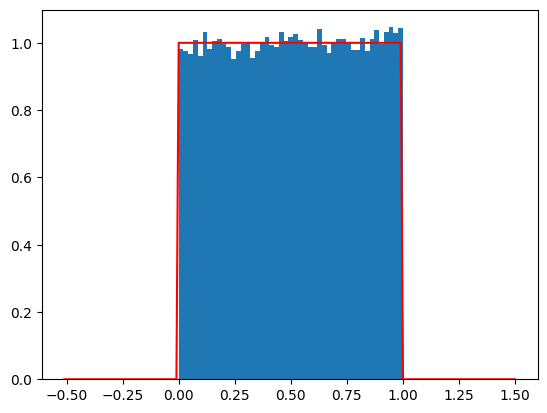

In [65]:
# 7
plt.hist(zeta1_rvs, density=True, bins="auto")
x = np.arange(-0.51, 1.51, 0.01)
y = uniform.pdf(x, loc=0, scale=1)
plt.plot(x, y, color="r")
plt.show()

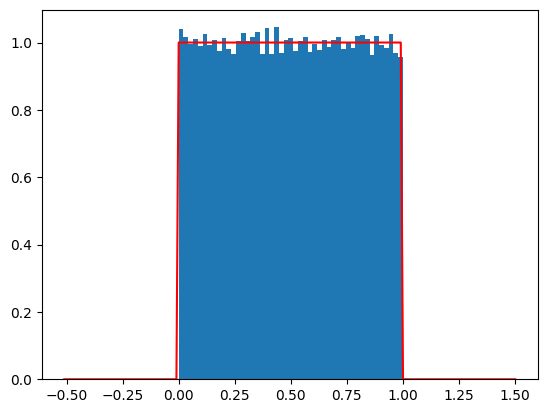

In [66]:
# 8
plt.hist(zeta2_rvs, density=True, bins="auto")
x = np.arange(-0.51, 1.51, 0.01)
y = uniform.pdf(x, loc=0, scale=1)
plt.plot(x, y, color="r")
plt.show()